In [4]:
from pathlib import Path
from copy import deepcopy
import json
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms


# ============================================================
# Configuration
# ============================================================

SEED = 1234

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

DATA_ROOT = Path("./data")
RESULTS_ROOT = Path("./keskar_reproduction")
CHECKPOINT_ROOT = RESULTS_ROOT / "checkpoints"

RESULTS_ROOT.mkdir(exist_ok=True)
CHECKPOINT_ROOT.mkdir(exist_ok=True)

# AUTHOR-SPECIFIED
SB_BATCH_SIZE = 256
LB_FRACTION = 0.10

# OUR REPRODUCTION CHOICE:
# PyTorch Adam defaults.
ADAM_KWARGS = {
    "lr": 1e-3,
    "betas": (0.9, 0.999),
    "eps": 1e-8,
    "weight_decay": 0.0,
}

# OUR REPRODUCTION CHOICE:
REL_IMPROVEMENT_TOL = 1e-4
PATIENCE = 10

# Generous safety caps. These are NOT the convergence criterion.
MAX_EPOCHS = {
    "F1": 300,
    "C1": 300,
    "C2": 300,
}

# OUR REPRODUCTION CHOICE
N_ALPHA = 61
ALPHAS = np.linspace(-1.0, 2.0, N_ALPHA)

# Ensure endpoints are represented exactly.
ALPHAS[np.argmin(np.abs(ALPHAS - 0.0))] = 0.0
ALPHAS[np.argmin(np.abs(ALPHAS - 1.0))] = 1.0

# Evaluation can use a larger batch because it does not affect training.
EVAL_BATCH_SIZE = 1024

# OUR REPRODUCTION CHOICE:
# Paper does not specify these architectural mechanics.
C1_CONV_PADDING = 2
C1_POOL_STRIDE = 3

C2_CONV_PADDING = 1
C2_POOL_STRIDE = 2


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)

print("PyTorch:", torch.__version__)
print("Device:", DEVICE)
print("Seed:", SEED)
print("Alpha endpoints present:",
      0.0 in ALPHAS, 1.0 in ALPHAS)

PyTorch: 2.14.1+cu130
Device: cuda
Seed: 1234
Alpha endpoints present: True True


In [5]:
# AUTHOR-SPECIFIED: no preprocessing for these datasets.
# ToTensor is needed to represent images as tensors; no normalization/augmentation.
transform = transforms.ToTensor()

mnist_train = datasets.MNIST(
    DATA_ROOT, train=True, download=True, transform=transform
)
mnist_test = datasets.MNIST(
    DATA_ROOT, train=False, download=True, transform=transform
)

cifar_train = datasets.CIFAR10(
    DATA_ROOT, train=True, download=True, transform=transform
)
cifar_test = datasets.CIFAR10(
    DATA_ROOT, train=False, download=True, transform=transform
)


def make_loaders(train_dataset, test_dataset):
    lb_batch_size = int(LB_FRACTION * len(train_dataset))

    # Training loaders.
    sb_loader = DataLoader(
        train_dataset,
        batch_size=SB_BATCH_SIZE,
        shuffle=True,
        drop_last=False,
    )

    lb_loader = DataLoader(
        train_dataset,
        batch_size=lb_batch_size,
        shuffle=True,
        drop_last=False,
    )

    # Complete-dataset evaluation.
    train_eval_loader = DataLoader(
        train_dataset,
        batch_size=EVAL_BATCH_SIZE,
        shuffle=False,
    )

    test_eval_loader = DataLoader(
        test_dataset,
        batch_size=EVAL_BATCH_SIZE,
        shuffle=False,
    )

    return sb_loader, lb_loader, train_eval_loader, test_eval_loader


mnist_loaders = make_loaders(mnist_train, mnist_test)
cifar_loaders = make_loaders(cifar_train, cifar_test)

print("MNIST:", len(mnist_train), len(mnist_test))
print("CIFAR-10:", len(cifar_train), len(cifar_test))

print("MNIST SB/LB:",
      mnist_loaders[0].batch_size,
      mnist_loaders[1].batch_size)

print("CIFAR SB/LB:",
      cifar_loaders[0].batch_size,
      cifar_loaders[1].batch_size)

MNIST: 60000 10000
CIFAR-10: 50000 10000
MNIST SB/LB: 256 6000
CIFAR SB/LB: 256 5000


In [6]:
# AUTHOR-SPECIFIED: no preprocessing for these datasets.
# ToTensor is needed to represent images as tensors; no normalization/augmentation.
transform = transforms.ToTensor()

mnist_train = datasets.MNIST(
    DATA_ROOT, train=True, download=True, transform=transform
)
mnist_test = datasets.MNIST(
    DATA_ROOT, train=False, download=True, transform=transform
)

cifar_train = datasets.CIFAR10(
    DATA_ROOT, train=True, download=True, transform=transform
)
cifar_test = datasets.CIFAR10(
    DATA_ROOT, train=False, download=True, transform=transform
)


def make_loaders(train_dataset, test_dataset):
    lb_batch_size = int(LB_FRACTION * len(train_dataset))

    # Training loaders.
    sb_loader = DataLoader(
        train_dataset,
        batch_size=SB_BATCH_SIZE,
        shuffle=True,
        drop_last=False,
    )

    lb_loader = DataLoader(
        train_dataset,
        batch_size=lb_batch_size,
        shuffle=True,
        drop_last=False,
    )

    # Complete-dataset evaluation.
    train_eval_loader = DataLoader(
        train_dataset,
        batch_size=EVAL_BATCH_SIZE,
        shuffle=False,
    )

    test_eval_loader = DataLoader(
        test_dataset,
        batch_size=EVAL_BATCH_SIZE,
        shuffle=False,
    )

    return sb_loader, lb_loader, train_eval_loader, test_eval_loader


mnist_loaders = make_loaders(mnist_train, mnist_test)
cifar_loaders = make_loaders(cifar_train, cifar_test)

print("MNIST:", len(mnist_train), len(mnist_test))
print("CIFAR-10:", len(cifar_train), len(cifar_test))

print("MNIST SB/LB:",
      mnist_loaders[0].batch_size,
      mnist_loaders[1].batch_size)

print("CIFAR SB/LB:",
      cifar_loaders[0].batch_size,
      cifar_loaders[1].batch_size)

MNIST: 60000 10000
CIFAR-10: 50000 10000
MNIST SB/LB: 256 6000
CIFAR SB/LB: 256 5000


In [7]:
class F1(nn.Module):
    def __init__(self):
        super().__init__()

        layers = []
        in_features = 784

        for _ in range(5):
            layers.extend([
                nn.Linear(in_features, 512),
                nn.BatchNorm1d(512),
                nn.ReLU(inplace=False),
            ])
            in_features = 512

        self.hidden = nn.Sequential(*layers)
        self.output = nn.Linear(512, 10)

    def forward(self, x):
        x = torch.flatten(x, 1)
        x = self.hidden(x)
        return self.output(x)


class C1(nn.Module):
    def __init__(self):
        super().__init__()

        # Paper: two [64,5,5,2]-MaxPool(3) stages.
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=5, stride=2,
                      padding=C1_CONV_PADDING),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=False),
            nn.MaxPool2d(kernel_size=3, stride=C1_POOL_STRIDE),

            nn.Conv2d(64, 64, kernel_size=5, stride=2,
                      padding=C1_CONV_PADDING),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=False),
            nn.MaxPool2d(kernel_size=3, stride=C1_POOL_STRIDE),
        )

        # Determine flatten dimension from our explicit padding/stride choice.
        with torch.no_grad():
            dummy = torch.zeros(2, 3, 32, 32)
            flat_dim = self.features(dummy).flatten(1).shape[1]

        self.flat_dim = flat_dim

        self.classifier = nn.Sequential(
            nn.Linear(flat_dim, 384),
            nn.BatchNorm1d(384),
            nn.ReLU(inplace=False),
            nn.Dropout(p=0.5),   # retention probability 0.5

            nn.Linear(384, 192),
            nn.BatchNorm1d(192),
            nn.ReLU(inplace=False),
            nn.Dropout(p=0.5),

            nn.Linear(192, 10),
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)


def conv_bn_relu(in_channels, out_channels):
    return [
        nn.Conv2d(
            in_channels,
            out_channels,
            kernel_size=3,
            stride=1,
            padding=C2_CONV_PADDING,
        ),
        nn.BatchNorm2d(out_channels),
        nn.ReLU(inplace=False),
    ]


class C2(nn.Module):
    def __init__(self):
        super().__init__()

        layers = []
        in_channels = 3

        # AUTHOR-SPECIFIED channel/depth sequence.
        stacks = [
            (64, 2),
            (128, 2),
            (256, 3),
            (512, 3),
            (512, 3),
        ]

        for out_channels, n_convs in stacks:
            for _ in range(n_convs):
                layers.extend(conv_bn_relu(in_channels, out_channels))
                in_channels = out_channels

            layers.append(
                nn.MaxPool2d(kernel_size=2, stride=C2_POOL_STRIDE)
            )

        self.features = nn.Sequential(*layers)

        with torch.no_grad():
            dummy = torch.zeros(2, 3, 32, 32)
            flat_dim = self.features(dummy).flatten(1).shape[1]

        self.flat_dim = flat_dim

        # "activation and properties ... as in B.3":
        # OUR INTERPRETATION includes BN/ReLU and 0.5-retention dropout.
        self.classifier = nn.Sequential(
            nn.Linear(flat_dim, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=False),
            nn.Dropout(p=0.5),
            nn.Linear(512, 10),
        )

    def forward(self, x):
        x = self.features(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)


MODEL_FACTORIES = {
    "F1": F1,
    "C1": C1,
    "C2": C2,
}

In [8]:
def print_tensor_shapes(model, input_shape):
    hooks = []

    def make_hook(name):
        def hook(module, inputs, output):
            if isinstance(output, torch.Tensor):
                print(
                    f"{name:45s} "
                    f"{module.__class__.__name__:18s} "
                    f"-> {tuple(output.shape)}"
                )
        return hook

    for name, module in model.named_modules():
        if name and len(list(module.children())) == 0:
            hooks.append(
                module.register_forward_hook(make_hook(name))
            )

    model.eval()

    with torch.no_grad():
        x = torch.zeros(*input_shape)
        y = model(x)

    for h in hooks:
        h.remove()

    print("FINAL:", tuple(y.shape))
    return y


for name, shape in [
    ("F1", (2, 1, 28, 28)),
    ("C1", (2, 3, 32, 32)),
    ("C2", (2, 3, 32, 32)),
]:
    print("\n", "=" * 70)
    print(name)
    model = MODEL_FACTORIES[name]()
    output = print_tensor_shapes(model, shape)

    assert output.shape == (2, 10), (
        f"{name} does not produce 10 logits."
    )


F1
hidden.0                                      Linear             -> (2, 512)
hidden.1                                      BatchNorm1d        -> (2, 512)
hidden.2                                      ReLU               -> (2, 512)
hidden.3                                      Linear             -> (2, 512)
hidden.4                                      BatchNorm1d        -> (2, 512)
hidden.5                                      ReLU               -> (2, 512)
hidden.6                                      Linear             -> (2, 512)
hidden.7                                      BatchNorm1d        -> (2, 512)
hidden.8                                      ReLU               -> (2, 512)
hidden.9                                      Linear             -> (2, 512)
hidden.10                                     BatchNorm1d        -> (2, 512)
hidden.11                                     ReLU               -> (2, 512)
hidden.12                                     Linear             -> (2, 

In [9]:
criterion = nn.CrossEntropyLoss(reduction="sum")


@torch.no_grad()
def evaluate(model, loader, device=DEVICE):
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_examples = 0

    for x, y in loader:
        x = x.to(device)
        y = y.to(device)

        logits = model(x)

        total_loss += criterion(logits, y).item()
        total_correct += (logits.argmax(1) == y).sum().item()
        total_examples += y.numel()

    return {
        "loss": total_loss / total_examples,
        "accuracy": 100.0 * total_correct / total_examples,
        "n": total_examples,
    }


def train_one_epoch(model, loader, optimizer, device=DEVICE):
    model.train()

    total_loss = 0.0
    total_examples = 0

    for x, y in loader:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = model(x)

        # Mean CE for optimization.
        loss = nn.functional.cross_entropy(
            logits, y, reduction="mean"
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * y.numel()
        total_examples += y.numel()

    return total_loss / total_examples

In [10]:
def train_to_convergence(
    model,
    train_loader,
    full_train_eval_loader,
    architecture,
    regime,
    seed,
):
    model = model.to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(),
        **ADAM_KWARGS,
    )

    best_loss = float("inf")
    consecutive_small_improvements = 0
    history = []

    max_epochs = MAX_EPOCHS[architecture]

    checkpoint_path = (
        CHECKPOINT_ROOT /
        f"{architecture}_{regime}_seed{seed}.pt"
    )

    stop_reason = "max_epoch_cap"

    for epoch in range(1, max_epochs + 1):
        t0 = time.time()

        minibatch_train_loss = train_one_epoch(
            model, train_loader, optimizer
        )

        # Required convergence quantity:
        # complete-training-set mean cross entropy.
        train_metrics = evaluate(
            model, full_train_eval_loader
        )
        current_loss = train_metrics["loss"]

        if np.isfinite(best_loss):
            relative_improvement = (
                (best_loss - current_loss) /
                max(abs(best_loss), 1e-12)
            )
        else:
            relative_improvement = float("inf")

        # A genuine improvement updates the best checkpoint.
        if current_loss < best_loss:
            best_loss = current_loss

            torch.save({
                "architecture": architecture,
                "regime": regime,
                "seed": seed,
                "epoch": epoch,
                "model_state": deepcopy(model.state_dict()),
                "full_train_loss": current_loss,
            }, checkpoint_path)

        # OUR REPRODUCTION CHOICE:
        # "relative improvement < tol for 10 consecutive epochs".
        #
        # Negative improvement (loss got worse) also counts as
        # "less than tol", which is intentional.
        if relative_improvement < REL_IMPROVEMENT_TOL:
            consecutive_small_improvements += 1
        else:
            consecutive_small_improvements = 0

        history.append({
            "epoch": epoch,
            "minibatch_train_loss": minibatch_train_loss,
            "full_train_loss": current_loss,
            "train_accuracy": train_metrics["accuracy"],
            "relative_improvement": relative_improvement,
            "small_improvement_count":
                consecutive_small_improvements,
            "seconds": time.time() - t0,
        })

        print(
            f"{architecture} {regime} | "
            f"epoch={epoch:03d} "
            f"full_loss={current_loss:.6f} "
            f"acc={train_metrics['accuracy']:.3f}% "
            f"rel_imp={relative_improvement:.3e} "
            f"patience={consecutive_small_improvements}/{PATIENCE}"
        )

        if consecutive_small_improvements >= PATIENCE:
            stop_reason = "converged"
            break

    # Use the best full-training-loss checkpoint.
    checkpoint = torch.load(
        checkpoint_path,
        map_location=DEVICE,
        weights_only=False,
    )

    model.load_state_dict(checkpoint["model_state"])

    metadata = {
        "architecture": architecture,
        "regime": regime,
        "seed": seed,
        "stop_reason": stop_reason,
        "epochs_run": epoch,
        "best_epoch": checkpoint["epoch"],
        "best_full_train_loss":
            checkpoint["full_train_loss"],
        "max_epoch_cap": max_epochs,
    }

    return model, pd.DataFrame(history), metadata

In [11]:
def clone_trainable_parameters(model):
    return {
        name: p.detach().cpu().clone()
        for name, p in model.named_parameters()
    }


def assert_trainable_unchanged(before, model):
    after = dict(model.named_parameters())

    for name, old_value in before.items():
        new_value = after[name].detach().cpu()

        assert torch.equal(old_value, new_value), (
            f"BN recalibration changed trainable parameter {name}"
        )


@torch.no_grad()
def recalibrate_batchnorm(
    model,
    train_loader,
    device=DEVICE,
):
    before = clone_trainable_parameters(model)

    bn_modules = []

    # Globally eval => dropout OFF.
    model.eval()

    for module in model.modules():
        if isinstance(
            module,
            (nn.BatchNorm1d, nn.BatchNorm2d, nn.BatchNorm3d)
        ):
            module.reset_running_stats()

            # Cumulative average over calibration batches.
            module.momentum = None

            # Only BN layers enter training mode.
            module.train()

            bn_modules.append(module)

    for x, _ in train_loader:
        x = x.to(device)
        _ = model(x)

    model.eval()

    assert_trainable_unchanged(before, model)

    return model

In [12]:
def clone_trainable_parameters(model):
    return {
        name: p.detach().cpu().clone()
        for name, p in model.named_parameters()
    }


def assert_trainable_unchanged(before, model):
    after = dict(model.named_parameters())

    for name, old_value in before.items():
        new_value = after[name].detach().cpu()

        assert torch.equal(old_value, new_value), (
            f"BN recalibration changed trainable parameter {name}"
        )


@torch.no_grad()
def recalibrate_batchnorm(
    model,
    train_loader,
    device=DEVICE,
    seed=SEED,
):
    before = clone_trainable_parameters(model)

    # Reset all BN running statistics.
    bn_modules = []

    for module in model.modules():
        if isinstance(
            module,
            (nn.BatchNorm1d, nn.BatchNorm2d, nn.BatchNorm3d)
        ):
            module.reset_running_stats()

            # cumulative moving average over calibration batches
            module.momentum = None
            bn_modules.append(module)

    # Enable training behavior so BN running stats update.
    # This also enables dropout. Fixing the seed makes this
    # stochastic calibration reproducible.
    model.train()

    # Preserve/restore RNG state so calibration does not alter
    # subsequent experimental randomness.
    cpu_rng_state = torch.get_rng_state()

    if torch.cuda.is_available():
        cuda_rng_state = torch.cuda.get_rng_state_all()
    else:
        cuda_rng_state = None

    set_seed(seed)

    for x, _ in train_loader:
        x = x.to(device)
        _ = model(x)

    torch.set_rng_state(cpu_rng_state)

    if cuda_rng_state is not None:
        torch.cuda.set_rng_state_all(cuda_rng_state)

    model.eval()

    assert_trainable_unchanged(before, model)

    return model

In [13]:
def make_bn_loader(dataset):
    return DataLoader(
        dataset,
        batch_size=EVAL_BATCH_SIZE,
        shuffle=False,
        drop_last=False,
    )

In [14]:
def evaluate_interpolation(
    architecture,
    sb_model,
    lb_model,
    train_dataset,
    train_eval_loader,
    test_loader,
    alphas=ALPHAS,
    seed=SEED,   # retained for interface/metadata consistency
):
    rows = []

    sb_model = sb_model.to(DEVICE)
    lb_model = lb_model.to(DEVICE)

    bn_loader = make_bn_loader(train_dataset)

    for i, alpha in enumerate(alphas):
        print(
            f"{architecture}: alpha {i+1}/{len(alphas)} "
            f"= {alpha:.3f}"
        )

        model = MODEL_FACTORIES[architecture]().to(DEVICE)

        # Paper's interpolation:
        # x(alpha) = alpha*x_LB + (1-alpha)*x_SB
        interpolate_trainable_parameters(
            model,
            sb_model,
            lb_model,
            float(alpha),
        )

        # Exact trainable-parameter endpoint checks.
        if alpha == 0.0:
            assert parameters_match(model, sb_model), (
                "alpha=0 does not exactly reproduce SB parameters"
            )

        if alpha == 1.0:
            assert parameters_match(model, lb_model), (
                "alpha=1 does not exactly reproduce LB parameters"
            )

        # OUR REPRODUCTION CHOICE:
        # recompute BN running statistics from one complete
        # training-set pass.
        #
        # NOTE: revised function no longer takes seed.
        recalibrate_batchnorm(
            model,
            bn_loader,
        )

        train_metrics = evaluate(
            model,
            train_eval_loader,
        )

        test_metrics = evaluate(
            model,
            test_loader,
        )

        rows.append({
            "architecture": architecture,
            "seed": seed,
            "alpha": float(alpha),

            "train_loss":
                train_metrics["loss"],
            "train_accuracy":
                train_metrics["accuracy"],

            "test_loss":
                test_metrics["loss"],
            "test_accuracy":
                test_metrics["accuracy"],
        })

        del model

        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return pd.DataFrame(rows)

In [15]:
def save_experiment(
    architecture,
    experiment,
    interpolation_results,
    seed=SEED,
):
    out_dir = RESULTS_ROOT / architecture
    out_dir.mkdir(parents=True, exist_ok=True)

    experiment["sb_history"].to_csv(
        out_dir / "sb_training_history.csv",
        index=False,
    )

    experiment["lb_history"].to_csv(
        out_dir / "lb_training_history.csv",
        index=False,
    )

    interpolation_results.to_csv(
        out_dir / "figure3_interpolation.csv",
        index=False,
    )

    metadata = {
        "architecture": architecture,
        "seed": seed,

        "author_specified": {
            "sb_batch_size": 256,
            "lb_batch_fraction": 0.10,
            "optimizer": "Adam",
            "objective": "mean cross entropy",
            "alpha_range": [-1.0, 2.0],
        },

        "our_reproduction_choices": {
            "adam": ADAM_KWARGS,
            "relative_improvement_tolerance":
                REL_IMPROVEMENT_TOL,
            "convergence_patience": PATIENCE,
            "max_epochs": MAX_EPOCHS[architecture],
            "alpha_points": N_ALPHA,
            "paired_identical_initialization": True,
            "bn_recalibration": (
                "reset running stats; one complete training-set "
                "pass at each interpolated point"
            ),
            "c1_conv_padding": C1_CONV_PADDING,
            "c1_pool_stride": C1_POOL_STRIDE,
            "c2_conv_padding": C2_CONV_PADDING,
            "c2_pool_stride": C2_POOL_STRIDE,
        },

        "sb_termination": experiment["sb_meta"],
        "lb_termination": experiment["lb_meta"],
    }

    with open(out_dir / "metadata.json", "w") as f:
        json.dump(metadata, f, indent=2)

    # Save final endpoint models as well.
    torch.save(
        experiment["sb_model"].state_dict(),
        out_dir / "sb_final.pt",
    )

    torch.save(
        experiment["lb_model"].state_dict(),
        out_dir / "lb_final.pt",
    )

    print("Saved to:", out_dir)

In [16]:
def plot_saved_interpolation(architecture):
    path = (
        RESULTS_ROOT /
        architecture /
        "figure3_interpolation.csv"
    )

    df = pd.read_csv(path)

    fig, ax_loss = plt.subplots(figsize=(7, 5))
    ax_acc = ax_loss.twinx()

    # Cross entropy
    ax_loss.plot(
        df["alpha"],
        df["train_loss"],
        label="Train loss",
    )
    ax_loss.plot(
        df["alpha"],
        df["test_loss"],
        linestyle="--",
        label="Test loss",
    )

    # Accuracy
    ax_acc.plot(
        df["alpha"],
        df["train_accuracy"],
        label="Train accuracy",
    )
    ax_acc.plot(
        df["alpha"],
        df["test_accuracy"],
        linestyle="--",
        label="Test accuracy",
    )

    ax_loss.axvline(0.0, linestyle=":", linewidth=1)
    ax_loss.axvline(1.0, linestyle=":", linewidth=1)

    ax_loss.set_xlabel(r"$\alpha$")
    ax_loss.set_ylabel("Mean cross entropy")
    ax_acc.set_ylabel("Classification accuracy (%)")
    ax_acc.set_ylim(0, 100)

    ax_loss.set_title(
        f"{architecture}: SB–LB parameter interpolation"
    )

    lines1, labels1 = ax_loss.get_legend_handles_labels()
    lines2, labels2 = ax_acc.get_legend_handles_labels()

    ax_loss.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc="best",
    )

    fig.tight_layout()

    out_path = (
        RESULTS_ROOT /
        architecture /
        "figure3_reproduction.png"
    )

    fig.savefig(out_path, dpi=200)
    plt.show()

    return df

In [17]:
def states_identical(model_a, model_b, trainable_only=True):
    if trainable_only:
        a = dict(model_a.named_parameters())
        b = dict(model_b.named_parameters())
    else:
        a = model_a.state_dict()
        b = model_b.state_dict()

    if a.keys() != b.keys():
        return False

    return all(
        torch.equal(a[k].detach().cpu(),
                    b[k].detach().cpu())
        for k in a
    )


def build_paired_models(architecture, seed=SEED):
    set_seed(seed)

    initial = MODEL_FACTORIES[architecture]()

    # Clone EXACTLY the same initialized state.
    sb_model = MODEL_FACTORIES[architecture]()
    lb_model = MODEL_FACTORIES[architecture]()

    initial_state = deepcopy(initial.state_dict())

    sb_model.load_state_dict(initial_state)
    lb_model.load_state_dict(initial_state)

    assert states_identical(sb_model, lb_model), (
        "SB/LB trainable parameters are not identical."
    )

    return sb_model, lb_model


def get_experiment_loaders(architecture):
    if architecture == "F1":
        return mnist_loaders

    if architecture in {"C1", "C2"}:
        return cifar_loaders

    raise ValueError(architecture)


def run_paired_training(architecture, seed=SEED):
    sb_loader, lb_loader, train_eval_loader, test_loader = (
        get_experiment_loaders(architecture)
    )

    sb_model, lb_model = build_paired_models(
        architecture, seed
    )

    print("Initial SB/LB parameters identical:",
          states_identical(sb_model, lb_model))

    print("SB batch size:", sb_loader.batch_size)
    print("LB batch size:", lb_loader.batch_size)

    sb_model, sb_history, sb_meta = train_to_convergence(
        sb_model,
        sb_loader,
        train_eval_loader,
        architecture,
        "SB",
        seed,
    )

    # Reset random seed so run metadata is reproducible.
    # The initialization itself is already identical.
    set_seed(seed)

    lb_model, lb_history, lb_meta = train_to_convergence(
        lb_model,
        lb_loader,
        train_eval_loader,
        architecture,
        "LB",
        seed,
    )

    return {
        "sb_model": sb_model,
        "lb_model": lb_model,
        "sb_history": sb_history,
        "lb_history": lb_history,
        "sb_meta": sb_meta,
        "lb_meta": lb_meta,
        "train_eval_loader": train_eval_loader,
        "test_loader": test_loader,
    }

In [18]:
def interpolate_trainable_parameters(
    target_model,
    sb_model,
    lb_model,
    alpha,
):
    target_params = dict(target_model.named_parameters())
    sb_params = dict(sb_model.named_parameters())
    lb_params = dict(lb_model.named_parameters())

    assert target_params.keys() == sb_params.keys() == lb_params.keys()

    with torch.no_grad():
        for name in target_params:
            target_params[name].copy_(
                alpha * lb_params[name] +
                (1.0 - alpha) * sb_params[name]
            )


def parameters_match(model_a, model_b):
    pa = dict(model_a.named_parameters())
    pb = dict(model_b.named_parameters())

    return all(
        torch.equal(pa[k].detach().cpu(),
                    pb[k].detach().cpu())
        for k in pa
    )


def test_interpolation_endpoints(architecture):
    sb, lb = build_paired_models(architecture)

    # Make LB actually different for this unit test.
    with torch.no_grad():
        first = next(lb.parameters())
        first.add_(0.123)

    interpolated = MODEL_FACTORIES[architecture]()

    interpolate_trainable_parameters(
        interpolated, sb, lb, alpha=0.0
    )
    assert parameters_match(interpolated, sb)

    interpolate_trainable_parameters(
        interpolated, sb, lb, alpha=1.0
    )
    assert parameters_match(interpolated, lb)

    print(architecture, "alpha endpoint test PASSED")

In [19]:
# ============================================================
# SANITY CHECK 1:
# Correct inputs -> 10 logits
# ============================================================

with torch.no_grad():
    assert F1()(torch.zeros(4, 1, 28, 28)).shape == (4, 10)
    assert C1()(torch.zeros(4, 3, 32, 32)).shape == (4, 10)
    assert C2()(torch.zeros(4, 3, 32, 32)).shape == (4, 10)

print("PASS: all architectures produce 10 logits.")


# ============================================================
# SANITY CHECK 2:
# Identical paired initialization
# ============================================================

for architecture in ["F1", "C1", "C2"]:
    sb, lb = build_paired_models(architecture, SEED)
    assert states_identical(sb, lb)

print("PASS: paired SB/LB initial parameters are identical.")


# ============================================================
# SANITY CHECK 3:
# Intended batch sizes
# ============================================================

assert mnist_loaders[0].batch_size == 256
assert mnist_loaders[1].batch_size == 6000

assert cifar_loaders[0].batch_size == 256
assert cifar_loaders[1].batch_size == 5000

print("PASS: SB/LB batch sizes are correct.")


# ============================================================
# SANITY CHECK 4:
# Exact interpolation endpoints
# ============================================================

for architecture in ["F1", "C1", "C2"]:
    test_interpolation_endpoints(architecture)

print("PASS: alpha=0 gives SB; alpha=1 gives LB.")


# ============================================================
# SANITY CHECK 5:
# BN recalibration cannot change trainable parameters
# ============================================================

model = F1().to(DEVICE)
before = clone_trainable_parameters(model)

mnist_bn_loader = make_bn_loader(mnist_train)

recalibrate_batchnorm(
    model,
    bn_loader,
)

assert_trainable_unchanged(before, model)

print("PASS: BN recalibration leaves trainable parameters unchanged.")

PASS: all architectures produce 10 logits.
PASS: paired SB/LB initial parameters are identical.
PASS: SB/LB batch sizes are correct.
F1 alpha endpoint test PASSED
C1 alpha endpoint test PASSED
C2 alpha endpoint test PASSED
PASS: alpha=0 gives SB; alpha=1 gives LB.


NameError: name 'bn_loader' is not defined

In [ ]:
# ============================================================
# SANITY CHECK 6:
# Short training decreases full-dataset loss
# ============================================================

set_seed(SEED)

model = F1().to(DEVICE)

sb_loader, _, train_eval_loader, _ = mnist_loaders

optimizer = torch.optim.Adam(
    model.parameters(),
    **ADAM_KWARGS,
)

initial = evaluate(model, train_eval_loader)["loss"]

for epoch in range(3):
    train_one_epoch(model, sb_loader, optimizer)

final = evaluate(model, train_eval_loader)["loss"]

print("Initial full-train loss:", initial)
print("Final full-train loss:  ", final)

assert final < initial, (
    "Short training did not decrease loss. Diagnose before "
    "launching the reproduction."
)

print("PASS: short F1 training decreases loss.")

In [30]:
experiment = run_paired_training("F1")

Initial SB/LB parameters identical: True
SB batch size: 256
LB batch size: 6000
F1 SB | epoch=001 full_loss=0.073406 acc=97.733% rel_imp=inf patience=0/10
F1 SB | epoch=002 full_loss=0.043644 acc=98.707% rel_imp=4.054e-01 patience=0/10
F1 SB | epoch=003 full_loss=0.033984 acc=98.948% rel_imp=2.213e-01 patience=0/10
F1 SB | epoch=004 full_loss=0.023129 acc=99.290% rel_imp=3.194e-01 patience=0/10
F1 SB | epoch=005 full_loss=0.022435 acc=99.310% rel_imp=3.001e-02 patience=0/10
F1 SB | epoch=006 full_loss=0.016270 acc=99.483% rel_imp=2.748e-01 patience=0/10
F1 SB | epoch=007 full_loss=0.013392 acc=99.580% rel_imp=1.769e-01 patience=0/10
F1 SB | epoch=008 full_loss=0.018253 acc=99.393% rel_imp=-3.629e-01 patience=1/10
F1 SB | epoch=009 full_loss=0.013473 acc=99.562% rel_imp=-6.000e-03 patience=2/10
F1 SB | epoch=010 full_loss=0.008484 acc=99.727% rel_imp=3.665e-01 patience=0/10
F1 SB | epoch=011 full_loss=0.009012 acc=99.702% rel_imp=-6.214e-02 patience=1/10
F1 SB | epoch=012 full_loss=0.01

KeyboardInterrupt: 

In [ ]:
print("SB termination:")
print(experiment["sb_meta"])

print("\nLB termination:")
print(experiment["lb_meta"])

sb_train = evaluate(
    experiment["sb_model"],
    experiment["train_eval_loader"]
)
sb_test = evaluate(
    experiment["sb_model"],
    experiment["test_loader"]
)

lb_train = evaluate(
    experiment["lb_model"],
    experiment["train_eval_loader"]
)
lb_test = evaluate(
    experiment["lb_model"],
    experiment["test_loader"]
)

print("\nF1 endpoints")
print("SB train:", sb_train)
print("SB test: ", sb_test)
print("LB train:", lb_train)
print("LB test: ", lb_test)

In [24]:
def run_complete_architecture(
    architecture,
    seed=SEED,
    existing_experiment=None,
):
    print("\n" + "=" * 80)
    print(f"COMPLETE EXPERIMENT: {architecture}")
    print("=" * 80)

    # --------------------------------------------------------
    # 1. Train endpoints, unless already supplied
    # --------------------------------------------------------

    if existing_experiment is None:
        experiment = run_paired_training(
            architecture,
            seed=seed,
        )
    else:
        experiment = existing_experiment

    # --------------------------------------------------------
    # 2. Endpoint diagnostics
    # --------------------------------------------------------

    sb_train = evaluate(
        experiment["sb_model"],
        experiment["train_eval_loader"],
    )

    sb_test = evaluate(
        experiment["sb_model"],
        experiment["test_loader"],
    )

    lb_train = evaluate(
        experiment["lb_model"],
        experiment["train_eval_loader"],
    )

    lb_test = evaluate(
        experiment["lb_model"],
        experiment["test_loader"],
    )

    print("\nSB termination:")
    print(experiment["sb_meta"])

    print("\nLB termination:")
    print(experiment["lb_meta"])

    print("\nEndpoint metrics:")
    print("SB train:", sb_train)
    print("SB test: ", sb_test)
    print("LB train:", lb_train)
    print("LB test: ", lb_test)

    # --------------------------------------------------------
    # 3. Select training dataset
    # --------------------------------------------------------

    if architecture == "F1":
        train_dataset = mnist_train
    elif architecture in {"C1", "C2"}:
        train_dataset = cifar_train
    else:
        raise ValueError(architecture)

    # --------------------------------------------------------
    # 4. 61-point Figure 3 interpolation
    # --------------------------------------------------------

    interpolation_results = evaluate_interpolation(
        architecture=architecture,
        sb_model=experiment["sb_model"],
        lb_model=experiment["lb_model"],
        train_dataset=train_dataset,
        train_eval_loader=experiment["train_eval_loader"],
        test_loader=experiment["test_loader"],
        alphas=ALPHAS,
        seed=seed,
    )

    # --------------------------------------------------------
    # 5. Save everything
    # --------------------------------------------------------

    save_experiment(
        architecture,
        experiment,
        interpolation_results,
        seed=seed,
    )

    # --------------------------------------------------------
    # 6. Endpoint interpolation diagnostics
    # --------------------------------------------------------

    print("\nInterpolation endpoints after BN recalibration:")

    endpoint_rows = interpolation_results[
        interpolation_results["alpha"].isin([0.0, 1.0])
    ]

    print(endpoint_rows.to_string(index=False))

    # --------------------------------------------------------
    # 7. Plot FROM SAVED CSV
    # --------------------------------------------------------

    plot_saved_interpolation(architecture)

    print("\nFINISHED:", architecture)

    return experiment, interpolation_results

In [32]:
# ============================================================
# RESTART / RECOVERY CELL
# Run this after all function/model/dataset definition cells,
# immediately before the F1 / C1 / C2 experiment cells.
# ============================================================

from pathlib import Path
import torch
import pandas as pd

print("=" * 70)
print("KESKAR REPRODUCTION — RECOVERY CHECK")
print("=" * 70)

# ------------------------------------------------------------
# 1. Recreate required directories
# ------------------------------------------------------------

RESULTS_ROOT = Path("./keskar_reproduction")
CHECKPOINT_ROOT = RESULTS_ROOT / "checkpoints"

RESULTS_ROOT.mkdir(parents=True, exist_ok=True)
CHECKPOINT_ROOT.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. Recreate dataset loaders
# ------------------------------------------------------------

mnist_loaders = make_loaders(mnist_train, mnist_test)
cifar_loaders = make_loaders(cifar_train, cifar_test)

print("\nBatch sizes:")
print(
    f"F1:    SB={mnist_loaders[0].batch_size}, "
    f"LB={mnist_loaders[1].batch_size}"
)
print(
    f"C1/C2: SB={cifar_loaders[0].batch_size}, "
    f"LB={cifar_loaders[1].batch_size}"
)

assert mnist_loaders[0].batch_size == 256
assert mnist_loaders[1].batch_size == 6000
assert cifar_loaders[0].batch_size == 256
assert cifar_loaders[1].batch_size == 5000


# ------------------------------------------------------------
# 3. Check completed F1 result
# ------------------------------------------------------------

f1_csv = RESULTS_ROOT / "F1" / "figure3_interpolation.csv"
f1_figure = RESULTS_ROOT / "F1" / "figure3_reproduction.png"

F1_COMPLETE = f1_csv.exists()

if F1_COMPLETE:
    f1_results = pd.read_csv(f1_csv)

    expected_alphas = set(
        np.round(np.asarray(ALPHAS, dtype=float), 10)
    )
    saved_alphas = set(
        np.round(f1_results["alpha"].to_numpy(dtype=float), 10)
    )

    assert expected_alphas == saved_alphas, (
        "F1 CSV exists but does not contain the complete "
        "61-point alpha grid."
    )

    print("\nF1 STATUS: COMPLETE")
    print(f"  Raw results: {f1_csv}")
    print(f"  Alpha points: {len(f1_results)}")

    if f1_figure.exists():
        print(f"  Figure:      {f1_figure}")
    else:
        print("  Figure file missing; raw results are intact.")
        print("  Run: plot_saved_interpolation('F1')")

else:
    print("\nF1 STATUS: NOT FOUND")
    print("Do NOT assume F1 is complete until its saved CSV is found.")


# ------------------------------------------------------------
# 4. Report C1/C2 status without starting/restarting anything
# ------------------------------------------------------------

def report_status(architecture):
    csv_path = (
        RESULTS_ROOT /
        architecture /
        "figure3_interpolation.csv"
    )

    sb_ckpt = (
        CHECKPOINT_ROOT /
        f"{architecture}_SB_seed{SEED}.pt"
    )

    lb_ckpt = (
        CHECKPOINT_ROOT /
        f"{architecture}_LB_seed{SEED}.pt"
    )

    if csv_path.exists():
        df = pd.read_csv(csv_path)

        expected = set(
            np.round(np.asarray(ALPHAS, dtype=float), 10)
        )
        saved = set(
            np.round(df["alpha"].to_numpy(dtype=float), 10)
        )

        if expected == saved:
            status = "COMPLETE"
        else:
            status = (
                f"PARTIAL RESULTS ({len(saved)}/{len(expected)} alphas)"
            )

    elif sb_ckpt.exists() and lb_ckpt.exists():
        status = "TRAINING CHECKPOINTS EXIST; INTERPOLATION NOT COMPLETE"

    elif sb_ckpt.exists():
        status = "SB CHECKPOINT EXISTS; LB NOT COMPLETE"

    elif lb_ckpt.exists():
        status = "LB CHECKPOINT EXISTS; SB NOT COMPLETE"

    else:
        status = "NOT STARTED"

    print(f"{architecture} STATUS: {status}")


print()
report_status("C1")
report_status("C2")


# ------------------------------------------------------------
# 5. Final guard
# ------------------------------------------------------------

print("\n" + "=" * 70)

if F1_COMPLETE:
    print("READY.")
    print("F1 will NOT be retrained.")
    print("Next full experiment should be C1.")
else:
    print("WARNING: completed F1 raw results were not located.")

print("=" * 70)

KESKAR REPRODUCTION — RECOVERY CHECK

Batch sizes:
F1:    SB=256, LB=6000
C1/C2: SB=256, LB=5000

F1 STATUS: COMPLETE
  Raw results: keskar_reproduction\F1\figure3_interpolation.csv
  Alpha points: 61
  Figure:      keskar_reproduction\F1\figure3_reproduction.png

C1 STATUS: TRAINING CHECKPOINTS EXIST; INTERPOLATION NOT COMPLETE
C2 STATUS: NOT STARTED

READY.
F1 will NOT be retrained.
Next full experiment should be C1.


In [42]:
# Load completed F1 results -- NO retraining
f1_results = pd.read_csv(
    RESULTS_ROOT / "F1" / "figure3_interpolation.csv"
)

print(f"Loaded {len(f1_results)} F1 interpolation points.")
print(f1_results[f1_results["alpha"].isin([0.0, 1.0])])

assert len(f1_results) == 61
print("\nF1 COMPLETE -- no need to rerun F1.")

Loaded 61 F1 interpolation points.
   architecture  seed  alpha  train_loss  train_accuracy  test_loss  \
20           F1  1234    0.0    0.001555       99.961667   0.072562   
40           F1  1234    1.0    0.000003      100.000000   0.078992   

    test_accuracy  
20          98.27  
40          98.47  

F1 COMPLETE -- no need to rerun F1.


In [38]:
f1_experiment, f1_results = run_complete_architecture(
    "F1",
    seed=SEED,
    existing_experiment=experiment,
)

NameError: name 'experiment' is not defined


COMPLETE EXPERIMENT: C1
Initial SB/LB parameters identical: True
SB batch size: 256
LB batch size: 5000
C1 SB | epoch=001 full_loss=1.194201 acc=58.082% rel_imp=inf patience=0/10
C1 SB | epoch=002 full_loss=1.151179 acc=58.004% rel_imp=3.603e-02 patience=0/10
C1 SB | epoch=003 full_loss=1.187557 acc=59.948% rel_imp=-3.160e-02 patience=1/10
C1 SB | epoch=004 full_loss=1.053177 acc=61.704% rel_imp=8.513e-02 patience=0/10
C1 SB | epoch=005 full_loss=1.041926 acc=62.284% rel_imp=1.068e-02 patience=0/10
C1 SB | epoch=006 full_loss=0.813167 acc=71.672% rel_imp=2.196e-01 patience=0/10
C1 SB | epoch=007 full_loss=0.980751 acc=65.784% rel_imp=-2.061e-01 patience=1/10
C1 SB | epoch=008 full_loss=0.762260 acc=73.016% rel_imp=6.260e-02 patience=0/10
C1 SB | epoch=009 full_loss=1.153364 acc=61.142% rel_imp=-5.131e-01 patience=1/10
C1 SB | epoch=010 full_loss=0.948469 acc=67.830% rel_imp=-2.443e-01 patience=2/10
C1 SB | epoch=011 full_loss=0.823680 acc=72.198% rel_imp=-8.058e-02 patience=3/10
C1 SB

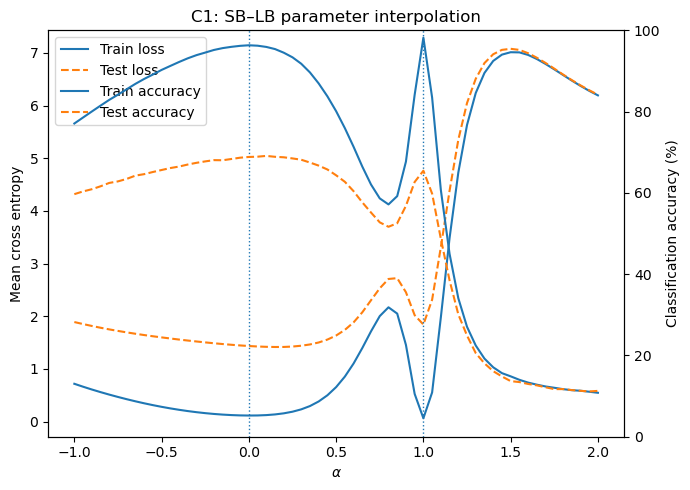


FINISHED: C1


In [44]:
c1_experiment, c1_results = run_complete_architecture(
    "C1",
    seed=SEED,
)


COMPLETE EXPERIMENT: C2
Initial SB/LB parameters identical: True
SB batch size: 256
LB batch size: 5000
C2 SB | epoch=001 full_loss=1.732005 acc=40.402% rel_imp=inf patience=0/10
C2 SB | epoch=002 full_loss=0.971080 acc=66.614% rel_imp=4.393e-01 patience=0/10
C2 SB | epoch=003 full_loss=0.890281 acc=69.092% rel_imp=8.321e-02 patience=0/10
C2 SB | epoch=004 full_loss=0.663486 acc=77.540% rel_imp=2.547e-01 patience=0/10
C2 SB | epoch=005 full_loss=0.515685 acc=82.674% rel_imp=2.228e-01 patience=0/10
C2 SB | epoch=006 full_loss=0.475338 acc=84.450% rel_imp=7.824e-02 patience=0/10
C2 SB | epoch=007 full_loss=0.404398 acc=85.786% rel_imp=1.492e-01 patience=0/10
C2 SB | epoch=008 full_loss=0.301061 acc=89.652% rel_imp=2.555e-01 patience=0/10
C2 SB | epoch=009 full_loss=0.381750 acc=87.468% rel_imp=-2.680e-01 patience=1/10
C2 SB | epoch=010 full_loss=0.503410 acc=83.974% rel_imp=-6.721e-01 patience=2/10
C2 SB | epoch=011 full_loss=0.182741 acc=93.788% rel_imp=3.930e-01 patience=0/10
C2 SB | 

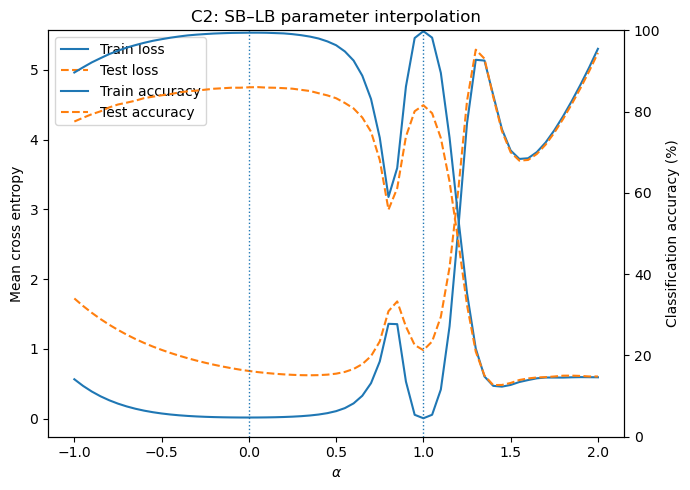


FINISHED: C2


In [45]:
c2_experiment, c2_results = run_complete_architecture(
    "C2",
    seed=SEED,
)

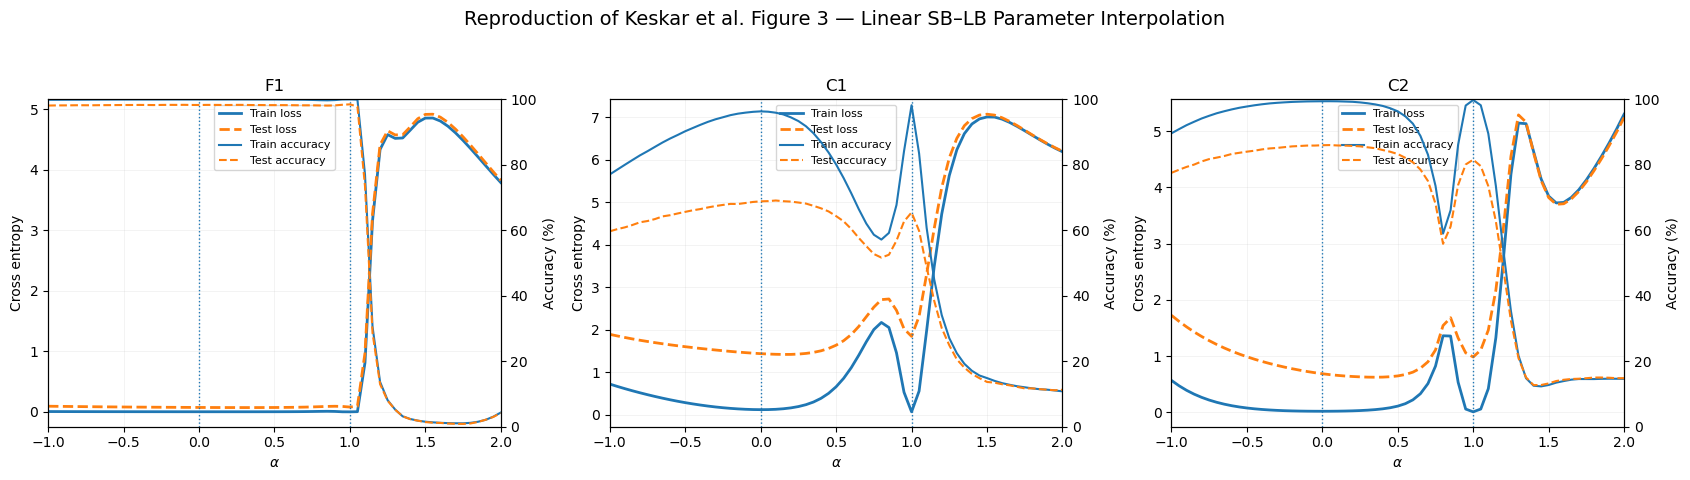


Final Figure 3 reproduction saved to:
keskar_reproduction\figure3_F1_C1_C2_reproduction.png

SB (alpha=0) and LB (alpha=1) measured endpoints:

F1
 alpha  train_loss  test_loss  train_accuracy  test_accuracy
   0.0    0.001555   0.072562       99.961667          98.27
   1.0    0.000003   0.078992      100.000000          98.47

C1
 alpha  train_loss  test_loss  train_accuracy  test_accuracy
   0.0    0.116248   1.435476          96.324          68.84
   1.0    0.064664   1.842995          98.196          65.45

C2
 alpha  train_loss  test_loss  train_accuracy  test_accuracy
   0.0    0.017149   0.684461          99.418          85.98
   1.0    0.006741   0.982434          99.792          81.57


In [49]:
# ============================================================
# FINAL FIGURE 3 REPRODUCTION — F1, C1, C2
#
# Plots ONLY saved experimental measurements.
# Does not train models or recompute interpolation.
# ============================================================

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RESULTS_ROOT = Path("./keskar_reproduction")

architectures = ["F1", "C1", "C2"]

# ------------------------------------------------------------
# Load and validate all three experimental result files
# ------------------------------------------------------------

results = {}

for architecture in architectures:
    path = (
        RESULTS_ROOT /
        architecture /
        "figure3_interpolation.csv"
    )

    if not path.exists():
        raise FileNotFoundError(
            f"{architecture} results not found:\n{path}"
        )

    df = pd.read_csv(path).sort_values("alpha")

    if len(df) != 61:
        raise RuntimeError(
            f"{architecture}: expected 61 alpha points, "
            f"found {len(df)}."
        )

    if not (df["alpha"] == 0.0).any():
        raise RuntimeError(
            f"{architecture}: alpha=0 SB endpoint missing."
        )

    if not (df["alpha"] == 1.0).any():
        raise RuntimeError(
            f"{architecture}: alpha=1 LB endpoint missing."
        )

    results[architecture] = df


# ------------------------------------------------------------
# Plot the three requested Figure 3 panels
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5),
    sharex=True,
)

for ax_loss, architecture in zip(axes, architectures):

    df = results[architecture]

    # Right-hand accuracy axis
    ax_acc = ax_loss.twinx()

    # -------------------------
    # Cross-entropy
    # -------------------------

    train_loss, = ax_loss.plot(
        df["alpha"],
        df["train_loss"],
        linewidth=2,
        label="Train loss",
    )

    test_loss, = ax_loss.plot(
        df["alpha"],
        df["test_loss"],
        linestyle="--",
        linewidth=2,
        label="Test loss",
    )

    # -------------------------
    # Classification accuracy
    # -------------------------

    train_acc, = ax_acc.plot(
        df["alpha"],
        df["train_accuracy"],
        linewidth=1.5,
        label="Train accuracy",
    )

    test_acc, = ax_acc.plot(
        df["alpha"],
        df["test_accuracy"],
        linestyle="--",
        linewidth=1.5,
        label="Test accuracy",
    )

    # -------------------------
    # SB/LB endpoints
    # -------------------------

    ax_loss.axvline(
        0.0,
        linestyle=":",
        linewidth=1,
    )

    ax_loss.axvline(
        1.0,
        linestyle=":",
        linewidth=1,
    )

    # -------------------------
    # Axes
    # -------------------------

    ax_loss.set_xlim(-1, 2)
    ax_acc.set_ylim(0, 100)

    ax_loss.set_xlabel(r"$\alpha$")
    ax_loss.set_ylabel("Cross entropy")
    ax_acc.set_ylabel("Accuracy (%)")

    ax_loss.set_title(architecture)

    ax_loss.grid(
        alpha=0.2,
        linewidth=0.5,
    )

    # One legend per panel
    lines = [
        train_loss,
        test_loss,
        train_acc,
        test_acc,
    ]

    labels = [
        line.get_label()
        for line in lines
    ]

    ax_loss.legend(
        lines,
        labels,
        loc="upper center",
        fontsize=8,
    )


# ------------------------------------------------------------
# Overall title / caption
# ------------------------------------------------------------

fig.suptitle(
    "Reproduction of Keskar et al. Figure 3 — "
    "Linear SB–LB Parameter Interpolation",
    fontsize=14,
)

fig.tight_layout(
    rect=[0, 0.03, 1, 0.94]
)

# ------------------------------------------------------------
# Save final combined figure
# ------------------------------------------------------------

output_path = (
    RESULTS_ROOT /
    "figure3_F1_C1_C2_reproduction.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("\nFinal Figure 3 reproduction saved to:")
print(output_path)


# ------------------------------------------------------------
# Print endpoint measurements for documentation
# ------------------------------------------------------------

print("\nSB (alpha=0) and LB (alpha=1) measured endpoints:")

for architecture in architectures:

    df = results[architecture]

    endpoints = df[
        df["alpha"].isin([0.0, 1.0])
    ][[
        "alpha",
        "train_loss",
        "test_loss",
        "train_accuracy",
        "test_accuracy",
    ]]

    print("\n" + architecture)
    print(endpoints.to_string(index=False))